# Segmented Linear Regression — ODP Site 1262

## Objective
Fit linear trends to separate intervals of the PETM-focused
bulk carbonate δ13C record.

## Model
Discontinuous piecewise-linear regression with two breakpoints
and three independently fitted linear segments.

## Limitations
- Breakpoints are estimated from sampled observations.
- Segment boundaries may contain sampling gaps.
- The model does not impose continuity.
- Residual autocorrelation and age-model uncertainty
  are not accounted for in this introductory exercise.

Load the original isotope dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root
cwd = Path.cwd()

if (cwd / "data" / "raw").is_dir():
    root = cwd
elif (cwd.parent / "data" / "raw").is_dir():
    root = cwd.parent
else:
    raise FileNotFoundError("Cannot locate data/raw.")

raw_file = root / "data" / "raw" / "208-1262_isotope.tab.tsv"

# Read the PANGAEA file
with raw_file.open(
    "r", encoding="utf-8-sig", errors="replace"
) as f:
    lines = f.readlines()

end_metadata = next(
    i for i, line in enumerate(lines)
    if line.strip() == "*/"
)

df = pd.read_csv(
    raw_file,
    sep="\t",
    skiprows=end_metadata + 1
)

carbon_col = "δ13C bulk carb [‰ PDB]"
age_col = "Age [ka BP]"

df["age_ma"] = df[age_col] / 1000

# Select the PETM-focused regression window
analysis = (
    df.loc[
        df["age_ma"].between(55.65, 56.30),
        ["age_ma", carbon_col]
    ]
    .dropna()
    .sort_values("age_ma", ascending=False)
    .reset_index(drop=True)
)

x = analysis["age_ma"].to_numpy()
y = analysis[carbon_col].to_numpy()

n = len(y)

print("Observations:", n)
print("Age range:", x.min(), "to", x.max())

Observations: 247
Age range: 55.65 to 56.299


Fit a simple linear regression

In [2]:
from scipy.stats import linregress

single_fit = linregress(x, y)

print("Slope:", single_fit.slope)
print("Intercept:", single_fit.intercept)
print("R-squared:", single_fit.rvalue ** 2)

Slope: 2.2848539105532586
Intercept: -125.79492904970652
R-squared: 0.4236903769233325


Create a function for linear segment fitting

In [3]:
def fit_segment(x_segment, y_segment):
    """
    Fit an ordinary least-squares line to one segment.
    Return its slope, intercept, RSS and predictions.
    """
    if len(x_segment) < 2:
        raise ValueError("A segment needs at least two observations.")

    if np.ptp(x_segment) == 0:
        raise ValueError("A segment needs at least two distinct ages.")

    slope, intercept = np.polyfit(
        x_segment, y_segment, deg=1
    )

    predicted = slope * x_segment + intercept

    rss = np.sum((y_segment - predicted) ** 2)

    return {
        "slope": slope,
        "intercept": intercept,
        "rss": rss,
        "predicted": predicted
    }

Search for the best two breakpoints

In [4]:
min_segment = 15

# Allowed boundaries: between distinct adjacent ages
valid_boundaries = [
    k for k in range(min_segment, n - min_segment + 1)
    if x[k - 1] != x[k]
]

best = {
    "rss": np.inf,
    "k1": None,
    "k2": None
}

for k1 in valid_boundaries:

    for k2 in valid_boundaries:

        if k2 - k1 < min_segment:
            continue

        if n - k2 < min_segment:
            continue

        if k2 <= k1:
            continue

        fit1 = fit_segment(x[:k1], y[:k1])
        fit2 = fit_segment(x[k1:k2], y[k1:k2])
        fit3 = fit_segment(x[k2:], y[k2:])

        total_rss = (
            fit1["rss"]
            + fit2["rss"]
            + fit3["rss"]
        )

        if total_rss < best["rss"]:
            best = {
                "rss": total_rss,
                "k1": k1,
                "k2": k2
            }

print("Best total RSS:", best["rss"])
print("First breakpoint index:", best["k1"])
print("Second breakpoint index:", best["k2"])

Best total RSS: 3.0375066868319758
First breakpoint index: 125
Second breakpoint index: 147


Calculate the fitted segment statistics

In [5]:
k1 = best["k1"]
k2 = best["k2"]

segments = [
    ("Older", x[:k1], y[:k1]),
    ("Middle", x[k1:k2], y[k1:k2]),
    ("Younger", x[k2:], y[k2:])
]

segment_results = []

for name, xs, ys in segments:

    fit = fit_segment(xs, ys)

    segment_results.append({
        "segment": name,
        "n": len(xs),
        "older_age_ma": xs.max(),
        "younger_age_ma": xs.min(),
        "slope_per_ma": fit["slope"],
        "slope_per_kyr": fit["slope"] / 1000,
        "rss": fit["rss"]
    })

segment_table = pd.DataFrame(segment_results)

display(segment_table)

print(
    "First boundary:",
    x[k1 - 1], "to", x[k1], "Ma"
)

print(
    "Second boundary:",
    x[k2 - 1], "to", x[k2], "Ma"
)

,segment,n,older_age_ma,younger_age_ma,slope_per_ma,slope_per_kyr,rss
0,Older,125,56.299,55.932,2.332331,0.002332,1.043264
1,Middle,22,55.905,55.870,4.179973,0.004180,1.029991
2,Younger,100,55.867,55.650,-3.327981,-0.003328,0.964251


First boundary: 55.932 to 55.905 Ma
Second boundary: 55.87 to 55.867 Ma


Plot segmented linear regression

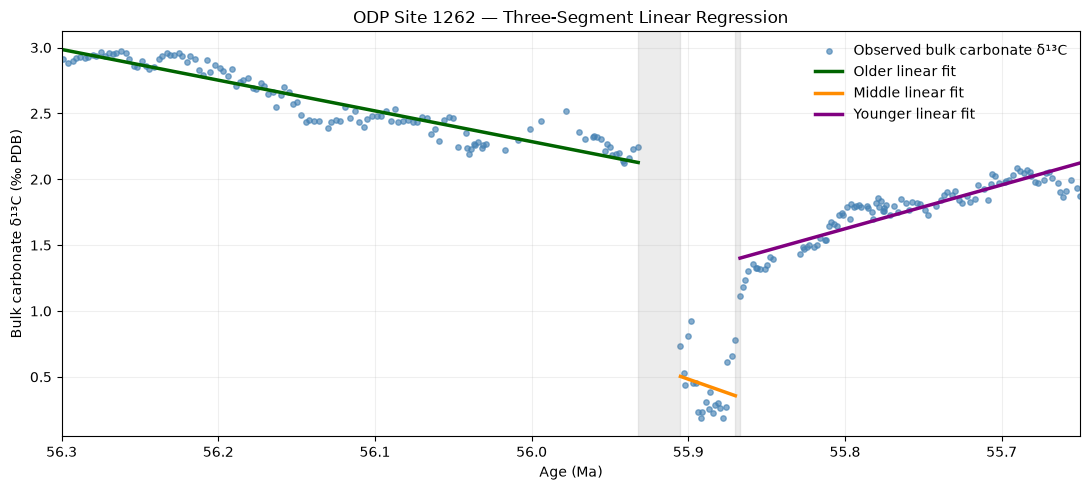

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(
    x, y,
    s=15,
    alpha=0.65,
    color="steelblue",
    label="Observed bulk carbonate δ¹³C"
)

colors = ["darkgreen", "darkorange", "purple"]

for (name, xs, ys), color in zip(segments, colors):

    fit = fit_segment(xs, ys)

    ax.plot(
        xs,
        fit["predicted"],
        linewidth=2.5,
        color=color,
        label=f"{name} linear fit"
    )

# Show intervals bracketing the fitted breakpoints
for k in [k1, k2]:
    ax.axvspan(
        x[k],
        x[k - 1],
        color="gray",
        alpha=0.15
    )

ax.set_xlim(56.30, 55.65)
ax.set_xlabel("Age (Ma)")
ax.set_ylabel("Bulk carbonate δ¹³C (‰ PDB)")
ax.set_title(
    "ODP Site 1262 — Three-Segment Linear Regression"
)

ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Compare the linear and constant-segment models

In [7]:
constant_rss = 14.967903
linear_rss = best["rss"]

print("Constant-segment RSS:", constant_rss)
print("Linear-segment RSS:", linear_rss)

print(
    "Additional RSS reduction (%):",
    100 * (constant_rss - linear_rss) / constant_rss
)

Constant-segment RSS: 14.967903
Linear-segment RSS: 3.0375066868319758
Additional RSS reduction (%): 79.70653145713214


Save the results and figure

In [8]:
results_dir = root / "results"
figure_dir = root / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

segment_table.to_csv(
    results_dir / "segmented_linear_three_segments.csv",
    index=False
)

fig.savefig(
    figure_dir / "segmented_linear_three_segments.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    figure_dir / "segmented_linear_three_segments.pdf",
    bbox_inches="tight"
)

print("Results and figures saved.")

Results and figures saved.


## Three-segment linear regression

A discontinuous piecewise-linear regression model was fitted to the ODP Site 1262 bulk carbonate δ¹³C record over 56.30–55.65 Ma.

Two breakpoints were estimated by exhaustive minimization of the combined residual sum of squares from three independently fitted linear segments. A minimum of 15 observations per segment was imposed, and boundaries between observations with identical reported ages were excluded.

The resulting model permits different linear trends and discontinuities between adjacent segments. The estimated breakpoints are reported as intervals bounded by neighboring observations rather than as precisely determined geological event ages.

The model is exploratory and does not explicitly account for serial correlation, irregular temporal sampling, analytical uncertainty or age-model uncertainty. In particular, a breakpoint located across a substantial sampling gap cannot resolve the timing or duration of the corresponding geological transition.

The segmented linear model will be compared with alternative model complexities and evaluated through sensitivity analyses before drawing geological conclusions.

Calculate geological-time slopes

In [9]:
# Copy the segment results so we preserve the original table
interpreted_segments = segment_table.copy()

# Convert slopes into the forward geological-time direction
interpreted_segments["forward_time_slope_per_kyr"] = (
    -interpreted_segments["slope_per_ma"] / 1000
)

# Add a simple description of each trend
def describe_trend(slope):
    if slope > 0:
        return "δ13C increases toward younger ages"
    elif slope < 0:
        return "δ13C decreases toward younger ages"
    else:
        return "No fitted linear change"

interpreted_segments["interpretation"] = (
    interpreted_segments["forward_time_slope_per_kyr"]
    .apply(describe_trend)
)

display(interpreted_segments)

,segment,n,older_age_ma,younger_age_ma,slope_per_ma,slope_per_kyr,rss,forward_time_slope_per_kyr,interpretation
0,Older,125,56.299,55.932,2.332331,0.002332,1.043264,-0.002332,δ13C decreases toward younger ages
1,Middle,22,55.905,55.870,4.179973,0.004180,1.029991,-0.004180,δ13C decreases toward younger ages
2,Younger,100,55.867,55.650,-3.327981,-0.003328,0.964251,0.003328,δ13C increases toward younger ages


In [10]:
breakpoint_summary = pd.DataFrame({
    "breakpoint": ["First", "Second"],
    "older_age_ma": [x[k1 - 1], x[k2 - 1]],
    "younger_age_ma": [x[k1], x[k2]]
})

breakpoint_summary["gap_kyr"] = (
    breakpoint_summary["older_age_ma"]
    - breakpoint_summary["younger_age_ma"]
) * 1000

display(breakpoint_summary)

,breakpoint,older_age_ma,younger_age_ma,gap_kyr
0,First,55.932,55.905,27.0
1,Second,55.870,55.867,3.0


Calculate the RSS for each model

In [11]:
# Number of observations
n = len(y)

# Model A: One constant mean
rss_constant_1 = np.sum(
    (y - y.mean()) ** 2
)

# Model B: Three constant segments
# Previously calculated on the same 247-observation window
rss_constant_3 = 14.967903

# Model C: One linear regression
single_linear = fit_segment(x, y)
rss_linear_1 = single_linear["rss"]

# Model D: Three linear segments
rss_linear_3 = best["rss"]

print("One constant mean:", rss_constant_1)
print("Three constant segments:", rss_constant_3)
print("One linear regression:", rss_linear_1)
print("Three linear segments:", rss_linear_3)

One constant mean: 116.29157604048585
Three constant segments: 14.967903
One linear regression: 67.01995435488402
Three linear segments: 3.0375066868319758


Calculate BIC

In [12]:
def calculate_bic(rss, n, p):
    if rss <= 0:
        raise ValueError("RSS must be positive.")
    return n * np.log(rss / n) + p * np.log(n)

model_comparison = pd.DataFrame({
    "model": [
        "One constant mean",
        "Three constant segments",
        "One linear regression",
        "Three linear segments"
    ],
    "rss": [
        rss_constant_1,
        rss_constant_3,
        rss_linear_1,
        rss_linear_3
    ],
    "parameters": [1, 5, 2, 8]
})

model_comparison["bic"] = [
    calculate_bic(rss, n, p)
    for rss, p in zip(
        model_comparison["rss"],
        model_comparison["parameters"]
    )
]

model_comparison = model_comparison.sort_values(
    "bic"
).reset_index(drop=True)

display(model_comparison)

,model,rss,parameters,bic
0,Three linear segments,3.037507,8,-1042.317671
1,Three constant segments,14.967903,5,-664.912675
2,One linear regression,67.019954,2,-311.167513
3,One constant mean,116.291576,1,-180.552677


Calculate ΔBIC

In [13]:
best_bic = model_comparison["bic"].min()

model_comparison["delta_bic"] = (
    model_comparison["bic"] - best_bic
)

display(model_comparison)

,model,rss,parameters,bic,delta_bic
0,Three linear segments,3.037507,8,-1042.317671,0.000000
1,Three constant segments,14.967903,5,-664.912675,377.404996
2,One linear regression,67.019954,2,-311.167513,731.150158
3,One constant mean,116.291576,1,-180.552677,861.764994


Plot the BIC results

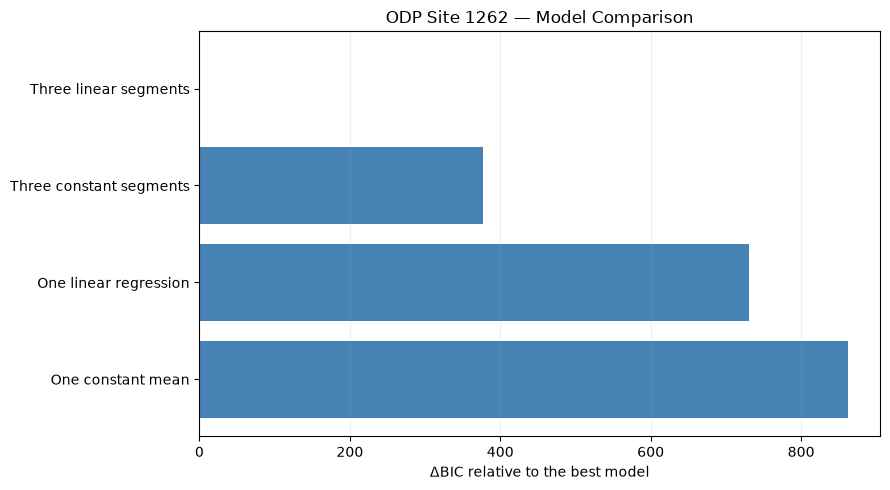

In [14]:
fig_bic, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    model_comparison["model"],
    model_comparison["delta_bic"],
    color="steelblue"
)

ax.set_xlabel("ΔBIC relative to the best model")
ax.set_title("ODP Site 1262 — Model Comparison")
ax.grid(axis="x", alpha=0.2)

ax.invert_yaxis()

plt.tight_layout()
plt.show()

Save results

In [15]:
results_dir = root / "results"
figure_dir = root / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

model_comparison.to_csv(
    results_dir / "segmented_model_comparison.csv",
    index=False
)

breakpoint_summary.to_csv(
    results_dir / "linear_breakpoint_summary.csv",
    index=False
)

interpreted_segments.to_csv(
    results_dir / "linear_segment_slopes.csv",
    index=False
)

fig_bic.savefig(
    figure_dir / "segmented_model_bic_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

print("All Lesson 14 results saved.")

All Lesson 14 results saved.


## Lesson 14 — Model comparison and interpretation

Piecewise-constant and piecewise-linear models were compared for the ODP Site 1262 bulk carbonate δ¹³C record over 56.30–55.65 Ma.

Four candidate models were evaluated: a single constant mean, three constant segments, a single linear regression, and three independent linear segments. Model fit was assessed using the residual sum of squares (RSS), and relative model performance was evaluated using the Bayesian Information Criterion (BIC).

For the segmented models, breakpoint locations were estimated from the data. An approximate complexity penalty was applied for the fitted breakpoints in addition to the segment means or linear coefficients.

The preferred model was identified as the candidate with the lowest BIC, and ΔBIC values were calculated relative to that model.

The fitted slopes were interpreted with respect to geological time, recognizing that numerical age in Ma increases toward the past. Breakpoints were reported as intervals bounded by adjacent observations rather than as precisely determined geological event ages.

This comparison remains exploratory because the models do not explicitly incorporate serial correlation, irregular temporal spacing, analytical uncertainty, or age-model uncertainty. Additional model complexities and sensitivity tests are required before geological event boundaries or rates of isotopic change can be inferred confidently.